In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. 读取地震数据
file_name = 'earthquakes-2026-10-14_11-23-28+0800.tsv'
Sig_Eqs = pd.read_csv(file_name, sep='\t')

# 统一列名格式，避免大小写或首尾空格导致 KeyError
Sig_Eqs.columns = Sig_Eqs.columns.str.upper().str.strip()

print(Sig_Eqs.head())
print("Columns:", Sig_Eqs.columns.tolist())


  SEARCH PARAMETERS    YEAR  MO  DY  HR  MN  SEC  TSU     VOL  \
0                []     NaN NaN NaN NaN NaN  NaN  NaN     NaN   
1               NaN -2150.0 NaN NaN NaN NaN  NaN  NaN     NaN   
2               NaN -2000.0 NaN NaN NaN NaN  NaN  1.0     NaN   
3               NaN -2000.0 NaN NaN NaN NaN  NaN  NaN     NaN   
4               NaN -1610.0 NaN NaN NaN NaN  NaN  3.0  1351.0   

                       LOCATION NAME  ...  TOTAL MISSING  \
0                                NaN  ...            NaN   
1      JORDAN:  BAB-A-DARAA,AL-KARAK  ...            NaN   
2                     SYRIA:  UGARIT  ...            NaN   
3                   TURKMENISTAN:  W  ...            NaN   
4  GREECE:  THERA ISLAND (SANTORINI)  ...            NaN   

   TOTAL MISSING DESCRIPTION  TOTAL INJURIES  TOTAL INJURIES DESCRIPTION  \
0                        NaN             NaN                         NaN   
1                        NaN             NaN                         NaN   
2                   

In [11]:
# 1.1 预处理国家/地区名称
# LOCATION NAME 并不总是 "城市, 国家"；常见格式也可能是 "国家: 地区"。
# 优先取冒号前的国家名；若没有冒号但有逗号，则取最后一段。
location = Sig_Eqs['LOCATION NAME'].fillna('').astype(str).str.strip()
country_from_colon = location.str.split(':', n=1).str[0].str.strip()
country_from_comma = location.str.split(',').str[-1].str.strip()
Sig_Eqs['COUNTRY'] = np.where(
    location.str.contains(':', regex=False),
    country_from_colon,
    np.where(location.str.contains(',', regex=False), country_from_comma, location)
)
Sig_Eqs.loc[Sig_Eqs['COUNTRY'].eq(''), 'COUNTRY'] = 'UNKNOWN'

# 死亡人数列转换为数值；优先使用 TOTAL DEATHS，若没有该列才使用 DEATHS
if 'TOTAL DEATHS' in Sig_Eqs.columns:
    deaths_col = 'TOTAL DEATHS'
elif 'DEATHS' in Sig_Eqs.columns:
    deaths_col = 'DEATHS'
else:
    raise KeyError("数据中没有 'TOTAL DEATHS' 或 'DEATHS' 列，请检查数据文件。")

Sig_Eqs[deaths_col] = pd.to_numeric(Sig_Eqs[deaths_col], errors='coerce').fillna(0)
country_deaths = Sig_Eqs.groupby('COUNTRY')[deaths_col].sum().reset_index()
country_deaths_sorted = country_deaths.sort_values(by=deaths_col, ascending=False)
print("Top 20 countries/regions by recorded earthquake deaths:")
print(country_deaths_sorted.head(20).to_string(index=False))


Top 20 countries/regions by recorded earthquake deaths:
     COUNTRY  TOTAL DEATHS
       CHINA     2106537.0
      TURKEY     1008349.0
        IRAN      745613.0
       SYRIA      418324.0
       ITALY      417297.0
       HAITI      323782.0
       JAPAN      319510.0
  AZERBAIJAN      319251.0
   INDONESIA      283164.0
     ARMENIA      175000.0
    PAKISTAN      143711.0
     ECUADOR      134445.0
      ISRAEL      128100.0
TURKMENISTAN      110412.0
        PERU       96301.0
      GREECE       83770.0
    PORTUGAL       82547.0
        IRAQ       70200.0
       CHILE       70175.0
       INDIA       61866.0


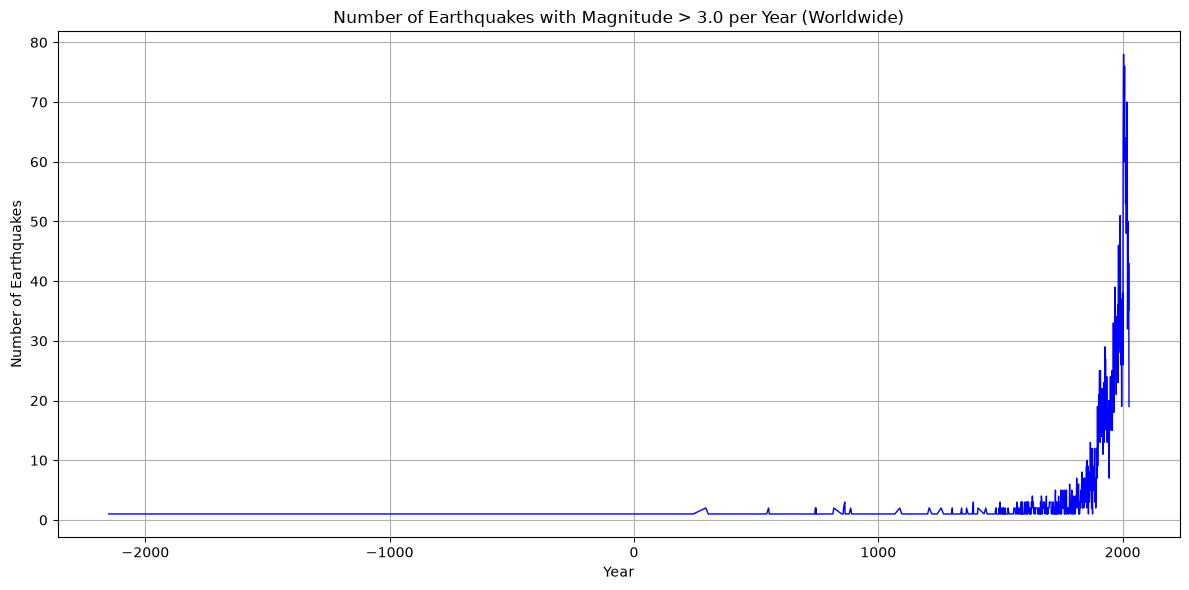

In [12]:
# 1.2 绘制震级大于 3 的地震年度数量
Sig_Eqs['MAG'] = pd.to_numeric(Sig_Eqs['MAG'], errors='coerce')
Sig_Eqs['YEAR'] = pd.to_numeric(Sig_Eqs['YEAR'], errors='coerce')
earthquakes_gt_3 = Sig_Eqs[
    (Sig_Eqs['MAG'] > 3.0) & Sig_Eqs['YEAR'].notna()
].copy()
earthquakes_gt_3['YEAR'] = earthquakes_gt_3['YEAR'].astype(int)
yearly_counts = earthquakes_gt_3.groupby('YEAR').size().reset_index(name='Count')

plt.figure(figsize=(12, 6))
plt.plot(yearly_counts['YEAR'], yearly_counts['Count'], color='blue', linewidth=1)
plt.title('Number of Earthquakes with Magnitude > 3.0 per Year (Worldwide)')
plt.xlabel('Year')
plt.ylabel('Number of Earthquakes')
plt.grid(True)
plt.tight_layout()
plt.show()

# 观察：通常可以看到时间序列在近现代（尤其是1950年之后）呈现急剧上升的趋势。
# 原因：这并不代表地球的地震活动真的变频繁了，而是因为现代地震监测网络更密集、技术更先进，以及数据记录更加完善。越早期的历史数据，只有极其重大的破坏性地震才会被记录，存在严重的“幸存者偏差”或记录缺失。

In [13]:
# 1.3 每个国家/地区的地震数量、最大震级地震日期和地点
def CountEq_LargestEq(country_name):
    country_data = Sig_Eqs[Sig_Eqs['COUNTRY'] == country_name].copy()
    total_eqs = len(country_data)
    if total_eqs == 0:
        return total_eqs, None, None

    country_data['MAG'] = pd.to_numeric(country_data['MAG'], errors='coerce')
    valid_mag_data = country_data.dropna(subset=['MAG'])
    if valid_mag_data.empty:
        return total_eqs, 'Unknown Date', 'Unknown Location'

    max_eq_row = valid_mag_data.loc[valid_mag_data['MAG'].idxmax()]
    year = str(int(max_eq_row['YEAR'])) if pd.notna(max_eq_row['YEAR']) else 'Unknown Year'
    mo = str(int(max_eq_row['MO'])).zfill(2) if pd.notna(max_eq_row['MO']) else 'Unknown Month'
    dy = str(int(max_eq_row['DY'])).zfill(2) if pd.notna(max_eq_row['DY']) else 'Unknown Day'
    date_str = f'{year}-{mo}-{dy}'
    location_name = max_eq_row['LOCATION NAME']
    return total_eqs, date_str, location_name

all_countries = Sig_Eqs['COUNTRY'].dropna().unique()
results = []
for country in all_countries:
    total_eqs, max_date, max_loc = CountEq_LargestEq(country)
    results.append({
        'Country/Region': country,
        'CountEq': total_eqs,
        'LargestEq_Date': max_date,
        'LargestEq_Location': max_loc
    })

results_df = pd.DataFrame(results).sort_values(by='CountEq', ascending=False)
print('Results sorted by total number of recorded earthquakes:')
print(results_df.to_string(index=False))


Results sorted by total number of recorded earthquakes:
                         Country/Region  CountEq                  LargestEq_Date                                   LargestEq_Location
                                  CHINA      629                      1668-07-25                            CHINA:  SHANDONG PROVINCE
                                  JAPAN      422                      2011-03-11                                       JAPAN:  HONSHU
                              INDONESIA      410                      2004-12-26          INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST
                                   IRAN      385                       856-12-22                                IRAN:  DAMGHAN, QUMIS
                                 TURKEY      345                      1939-12-26                                    TURKEY:  ERZINCAN
                                  ITALY      337                      1915-01-13                   ITALY:  MARSICA, AVEZZANO, ABRUZZI
      

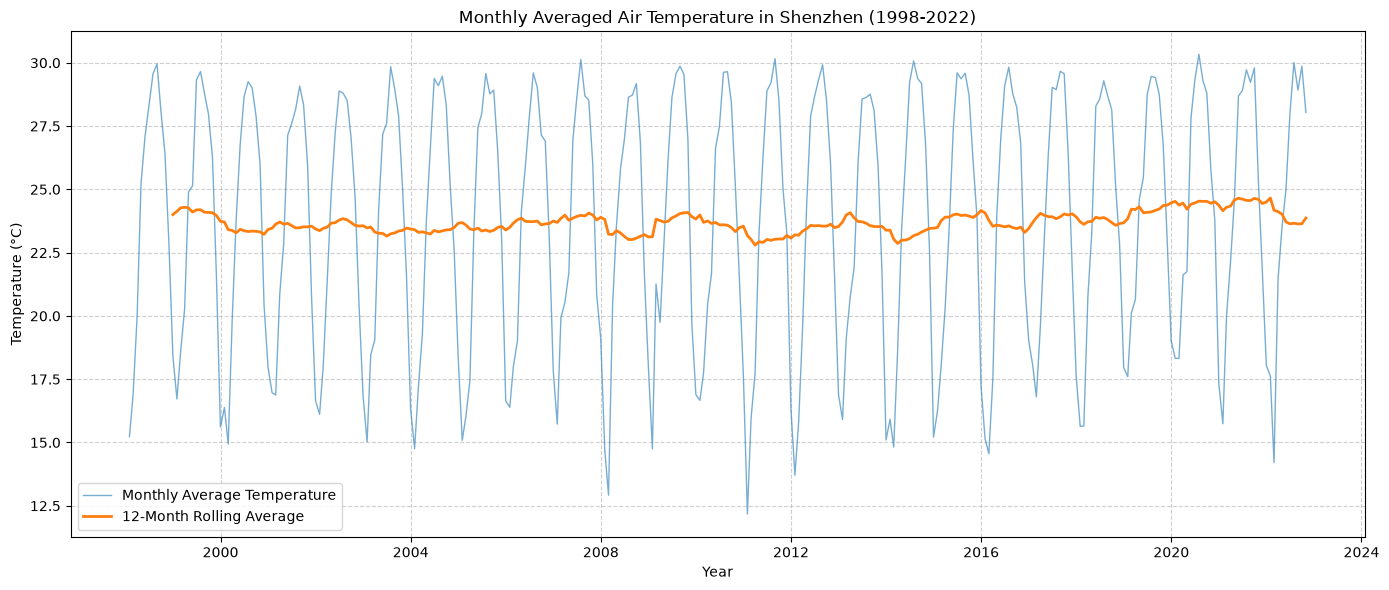

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 2. 读取深圳宝安气温数据
df = pd.read_csv('Baoan_Weather_1998_2022.csv')
weather_data = df[['DATE', 'TMP']].copy()
weather_data['DATE'] = pd.to_datetime(weather_data['DATE'], errors='coerce')

# TMP 示例：+0164,1 表示 16.4°C；+9999,9 / -9999,9 表示缺失
weather_data['TMP'] = (
    weather_data['TMP'].astype(str).str.split(',').str[0]
)
weather_data['TMP'] = pd.to_numeric(weather_data['TMP'], errors='coerce')
weather_data.loc[weather_data['TMP'].abs() == 9999, 'TMP'] = np.nan
weather_data['TMP'] = weather_data['TMP'] / 10.0
weather_data = weather_data.dropna(subset=['DATE', 'TMP']).copy()
weather_data = weather_data.set_index('DATE').sort_index()

# 按月计算平均气温
monthly_avg_temp = weather_data['TMP'].resample('ME').mean()
rolling_avg = monthly_avg_temp.rolling(window=12, min_periods=12).mean()

plt.figure(figsize=(14, 6))
plt.plot(monthly_avg_temp.index, monthly_avg_temp, linewidth=1, alpha=0.6, label='Monthly Average Temperature')
plt.plot(rolling_avg.index, rolling_avg, linewidth=2, label='12-Month Rolling Average')
plt.title('Monthly Averaged Air Temperature in Shenzhen (1998-2022)')
plt.xlabel('Year')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#虽然过去20多年里气温有起伏（比如中间有一段相对平缓的时期），但整体来看，特别是从2010年之后，深圳的长期平均气温确实在缓慢上升。

In [15]:
# 3. 读取 IBTrACS 热带气旋数据
import pandas as pd
import matplotlib.pyplot as plt

# 只读取前 17 列；跳过 IBTrACS 文件中的说明行
# 如果当前下载版本的列布局不同，请根据文件说明调整 usecols / skiprows。
df = pd.read_csv(
    'ibtracs.ALL.list.v04r00.csv', usecols=range(17), skiprows=[1, 2],
    parse_dates=['ISO_TIME'], na_values=[' NOT_NAMED', ' NAME'], low_memory=False
)
for col in ['WMO_WIND', 'LON', 'LAT', 'SEASON']:
    df[col] = pd.to_numeric(df[col], errors='coerce')
    
#根据数据特征，使用了 skiprows 跳过文件头部的单位行，用 parse_dates 解析时间，并用 na_values 处理无效的风暴名称

In [16]:
# 3.1 前10名（名称）
print("3.1 Top 10 largest hurricanes by WMO_WIND:")
print(largest_hurricanes.head(10)['NAME'].to_string())

# 3.2 前20名（风速）
print("\n3.2 Top 20 strongest-wind hurricanes (WMO_WIND):")
print(largest_hurricanes.head(20)['WMO_WIND'].to_string())

3.1 Top 10 largest hurricanes by WMO_WIND:
SID
2015293N13266     PATRICIA
1980214N11330        ALLEN
2005289N18282        WILMA
1997253N12255        LINDA
1988253N12306      GILBERT
1935241N23291    NOT_NAMED
2019236N10314       DORIAN
2009288N07267         RICK
1998295N12284        MITCH
2017242N16333         IRMA

3.2 Top 20 strongest-wind hurricanes (WMO_WIND):
SID
2015293N13266    185.0
1980214N11330    165.0
2005289N18282    160.0
1997253N12255    160.0
1988253N12306    160.0
1935241N23291    160.0
2019236N10314    160.0
2009288N07267    155.0
1998295N12284    155.0
2017242N16333    155.0
2005261N21290    155.0
2017260N12310    150.0
1955265N13307    150.0
1979238N12324    150.0
1977242N27272    150.0
2007244N12303    150.0
2007225N12331    150.0
2005236N23285    150.0
1994222N11267    150.0
1992230N11325    150.0


In [17]:
# 3.3 按流域统计数据点数量
basin_counts = df['BASIN'].value_counts(dropna=False)
print('Datapoints by basin:')
print(basin_counts)


Datapoints by basin:
BASIN
WP     236576
SI     160668
NaN    124881
SP      67119
EP      62412
NI      55401
SA        119
Name: count, dtype: int64


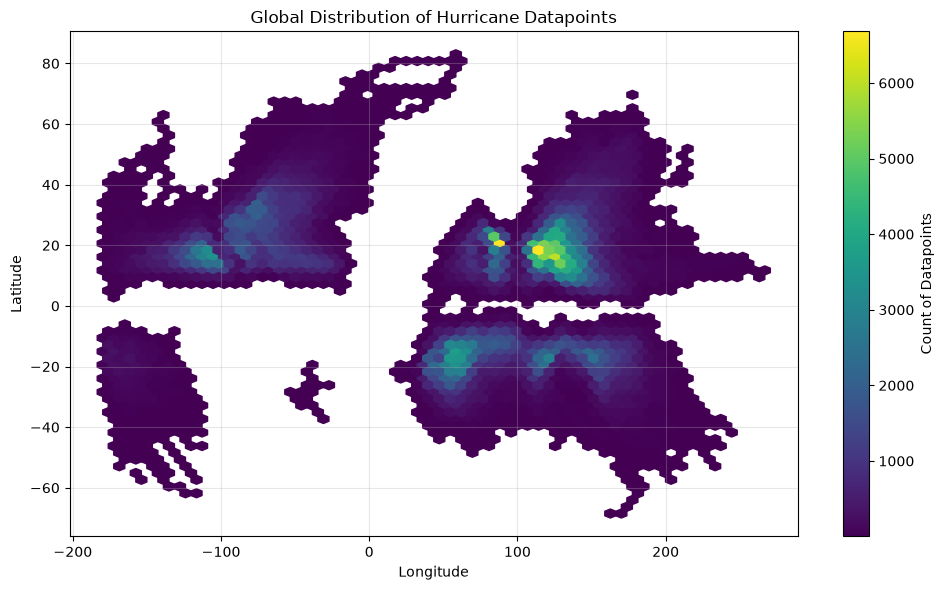

In [18]:
# 3.4 绘制经纬度六边形密度图
valid_geo = df.dropna(subset=['LON', 'LAT'])
plt.figure(figsize=(10, 6))
plt.hexbin(valid_geo['LON'], valid_geo['LAT'], gridsize=60, cmap='viridis', mincnt=1)
plt.colorbar(label='Count of Datapoints')
plt.title('Global Distribution of Hurricane Datapoints')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



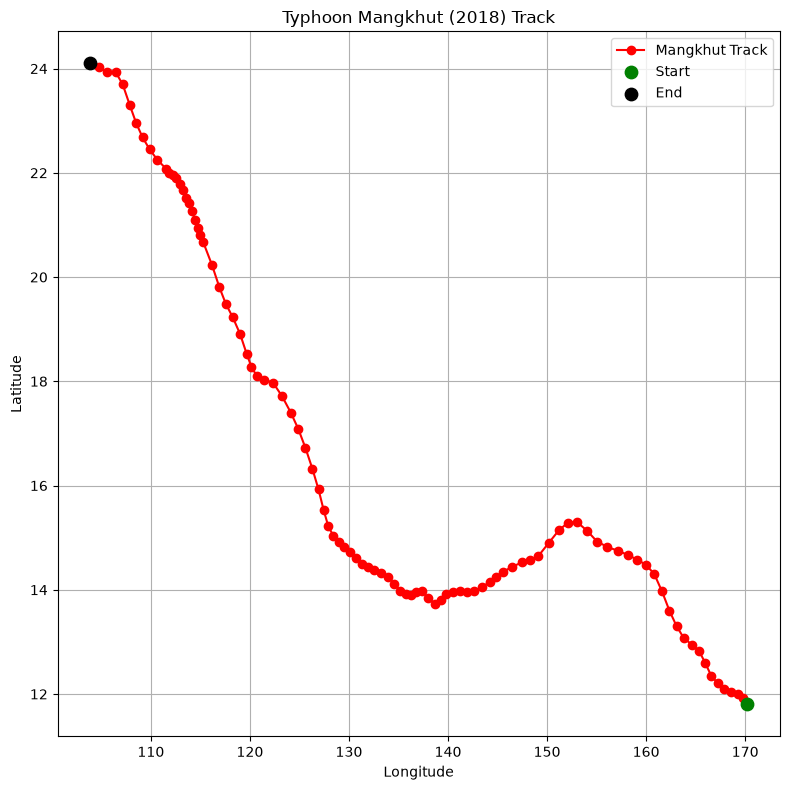

In [19]:
# 3.5 找到 2018 年台风山竹并绘制轨迹
mangkhut = df[
    (df['NAME'].astype(str).str.strip().str.upper() == 'MANGKHUT') &
    (df['SEASON'] == 2018)
].dropna(subset=['ISO_TIME', 'LON', 'LAT']).sort_values('ISO_TIME')

if mangkhut.empty:
    print('No track data found for Mangkhut (2018). Please check NAME, SEASON, and the imported columns.')
else:
    plt.figure(figsize=(8, 8))
    plt.plot(mangkhut['LON'], mangkhut['LAT'], marker='o', linestyle='-', color='red', label='Mangkhut Track')
    plt.scatter(mangkhut['LON'].iloc[0], mangkhut['LAT'].iloc[0], color='green', s=80, label='Start', zorder=5)
    plt.scatter(mangkhut['LON'].iloc[-1], mangkhut['LAT'].iloc[-1], color='black', s=80, label='End', zorder=5)
    plt.title('Typhoon Mangkhut (2018) Track')
    plt.xlabel('Longitude')
    plt.ylabel('Latitude')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()



In [20]:
# 3.6 筛选 1970 年以来的 WP 和 EP 流域数据
# 确保年份可用于筛选
if 'SEASON' not in df.columns or 'BASIN' not in df.columns:
    raise KeyError('缺少 SEASON 或 BASIN 列，请检查读取的 IBTrACS 列范围。')
df_filtered = df[(df['SEASON'] >= 1970) & (df['BASIN'].isin(['WP', 'EP']))].copy()
print(f'Filtered dataset shape: {df_filtered.shape}')



Filtered dataset shape: (176352, 17)


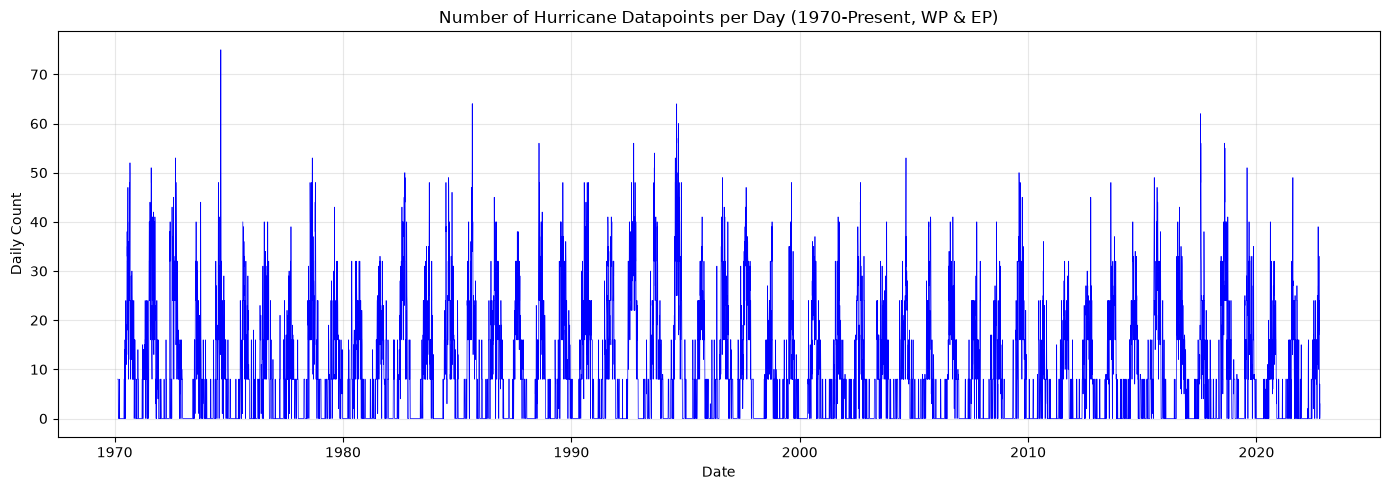

In [21]:
# 3.7 统计并绘制每天的数据点数量
valid_time = df_filtered.dropna(subset=['ISO_TIME']).copy()
daily_counts = valid_time.set_index('ISO_TIME').resample('D').size()
plt.figure(figsize=(14, 5))
plt.plot(daily_counts.index, daily_counts.values, color='blue', linewidth=0.5)
plt.title('Number of Hurricane Datapoints per Day (1970-Present, WP & EP)')
plt.xlabel('Date')
plt.ylabel('Daily Count')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()



In [22]:
# 3.8 计算每日数据点数量的气候态
# 使用 resample('D') 得到的 daily_counts，其中没有记录的日期会记为 0。
# 对每个年内日期，计算不同年份的每日数据点数量平均值，而不是直接计数总和。
daily_df = daily_counts.rename('count').reset_index()
daily_df.columns = ['ISO_TIME', 'count']
daily_df['day_of_year'] = daily_df['ISO_TIME'].dt.dayofyear
climatology = daily_df.groupby('day_of_year')['count'].mean()
print('Climatology (first few day-of-year values):')
print(climatology.head())


Climatology (first few day-of-year values):
day_of_year
1    1.596154
2    1.384615
3    1.423077
4    1.788462
5    2.019231
Name: count, dtype: float64


In [23]:
# 3.9 计算每日计数相对于对应年内日期气候态的异常值
daily_df['climatology'] = daily_df['day_of_year'].map(climatology)
daily_df['anomaly'] = daily_df['count'] - daily_df['climatology']
print(daily_df[['ISO_TIME', 'count', 'climatology', 'anomaly']].head())


    ISO_TIME  count  climatology   anomaly
0 1970-02-19      8     0.981132  7.018868
1 1970-02-20      8     0.905660  7.094340
2 1970-02-21      8     0.811321  7.188679
3 1970-02-22      8     0.622642  7.377358
4 1970-02-23      8     0.509434  7.490566


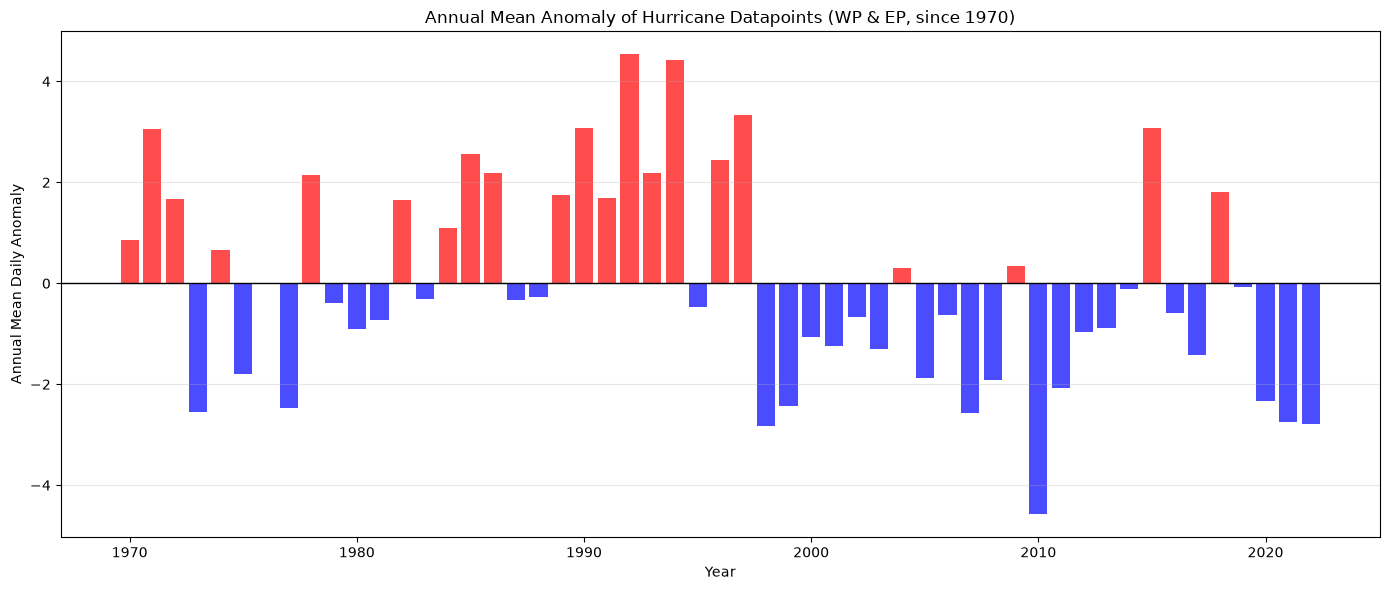

In [24]:
# 3.10 将每日异常值按年求平均并绘图
# 使用年度平均异常，避免把每日异常简单求和后误解为年度活动总量。
annual_anomaly = daily_df.set_index('ISO_TIME')['anomaly'].resample('YE').mean()
plt.figure(figsize=(14, 6))
colors = ['red' if value > 0 else 'blue' for value in annual_anomaly]
plt.bar(annual_anomaly.index.year, annual_anomaly.values, color=colors, alpha=0.7)
plt.axhline(0, color='black', linewidth=1)
plt.title('Annual Mean Anomaly of Hurricane Datapoints (WP & EP, since 1970)')
plt.xlabel('Year')
plt.ylabel('Annual Mean Daily Anomaly')
plt.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

#1990年代初中期（以1992、1994年为极值）和2015年飓风活动异常偏多，而1998年至2010年代初（特别是2010年最低）及近年则显著偏少，整体呈现出强烈的年际波动。

In [25]:
# 4 CFC-11 数据分析
import xarray as xr
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import warnings
warnings.filterwarnings('ignore')

#4.1加载文件，并清理可能存在的缺失值或质量不佳的数据点。
file_path = 'agage_mhd_cfc-11_monthly-baseline-20260716.nc'
ds = xr.open_dataset(file_path)
df = ds[['mf']].to_dataframe().reset_index()
df['time'] = pd.to_datetime(df['time'], errors='coerce')
df['mf'] = pd.to_numeric(df['mf'], errors='coerce')
df_clean = df.dropna(subset=['time', 'mf']).copy()
df_clean = df_clean.set_index('time').sort_index()
print(f'Cleaned data: {len(df_clean)} months/records')
print(df_clean.head())


Cleaned data: 459 months/records
                    mf
time                  
1987-02-01  240.464310
1987-03-01  237.823792
1987-04-01  237.564331
1987-05-01  239.093674
1987-06-01  240.247131


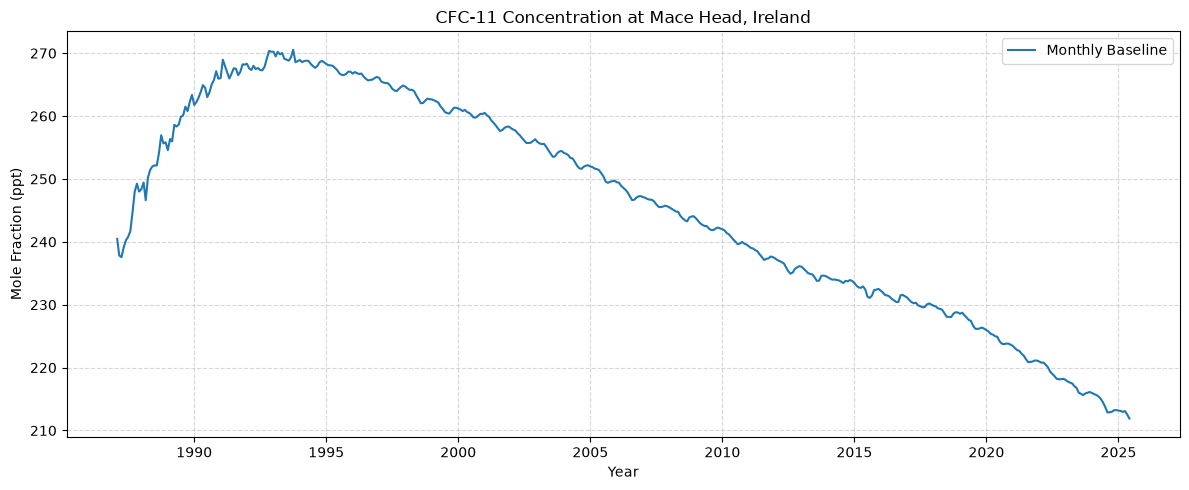

In [26]:
# 4.2 绘制 CFC-11 月度基线浓度时间序列
plt.figure(figsize=(12, 5))
plt.plot(df_clean.index, df_clean['mf'], linewidth=1.5, label='Monthly Baseline')
plt.title('CFC-11 Concentration at Mace Head, Ireland')
plt.xlabel('Year')
plt.ylabel('Mole Fraction (ppt)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()



In [27]:
# 4.3 描述性统计、线性趋势、正态性、自相关和季节性检查
print('=' * 40)
print('4.3 Statistical Checks Results')
print('=' * 40)
y = df_clean['mf'].to_numpy()
x_years = (df_clean.index - df_clean.index[0]).days / 365.25

print('\n[Check 1] Descriptive Statistics:')
print(f'Mean: {np.mean(y):.2f} ppt')
print(f'Median: {np.median(y):.2f} ppt')
print(f'Standard Deviation: {np.std(y, ddof=1):.2f} ppt')
print(f'Max: {np.max(y):.2f} ppt, Min: {np.min(y):.2f} ppt')
#在观测期内，CFC-11 的平均浓度约为 245.79 ppt，中位数为 246.71 ppt。数据跨度较大，最高达 270.54 ppt，最低降至 211.90 ppt，标准差为 16.88 ppt，显示出明显的波动。

print('\n[Check 2] Linear Trend Analysis:')
slope, intercept, r_value, p_value, std_err = stats.linregress(x_years, y)
print(f'Slope: {slope:.4f} ppt/year')
print(f'R-squared: {r_value**2:.4f}')
print(f'P-value: {p_value:.4e}')
print('Note: this is a single linear trend across the full period; it may hide changes in trend over time.')
#线性趋势分析显示，浓度呈现极显著的下降趋势，平均每年下降1.3832 ppt。这印证了《蒙特利尔议定书》实施后消耗臭氧层物质被淘汰的实际效果。

print('\n[Check 3] Normality Test (Shapiro-Wilk):')
# 固定随机种子以便复现；Shapiro-Wilk 对大样本很敏感，结果应结合图形判断。
rng = np.random.default_rng(42)
sample_y = rng.choice(y, size=500, replace=False) if len(y) > 500 else y
stat, p_norm = stats.shapiro(sample_y)
print(f'Shapiro-Wilk Statistic: {stat:.4f}, P-value: {p_norm:.4e}')
print('Evidence against normality (p < 0.05).' if p_norm < 0.05 else 'No significant evidence against normality (p >= 0.05).')
#Shapiro-Wilk 检验拒绝正态性假设。这在具有单向长期趋势的环境时间序列中非常普遍。

print('\n[Check 4] Lag-1 Autocorrelation:')
lag1_corr = df_clean['mf'].autocorr(lag=1)
print(f'Lag-1 Autocorrelation: {lag1_corr:.4f}')
print('Note: strong autocorrelation means ordinary regression p-values may be unreliable without time-series adjustment.')
#一阶自相关高达 0.9993，说明相邻时间的浓度高度依赖。

print('\n[Check 5] Simple Monthly Means (may be affected by long-term trend):')
df_clean['Month'] = df_clean.index.month
monthly_means = df_clean.groupby('Month')['mf'].mean()
print(f'Max month mean: {monthly_means.max():.2f} ppt, Min month mean: {monthly_means.min():.2f} ppt')
print(f'Monthly mean range: {monthly_means.max() - monthly_means.min():.2f} ppt')
print('Note: because concentration changes over time, these raw monthly means are not a pure seasonal amplitude.')
#分组计算显示，月度均值的极差仅为 1.37 ppt。这说明长期的急剧下降趋势完全主导了数据变异，导致原始月度数据中很难直接观察到纯粹的季节性振幅。

4.3 Statistical Checks Results

[Check 1] Descriptive Statistics:
Mean: 245.79 ppt
Median: 246.71 ppt
Standard Deviation: 16.88 ppt
Max: 270.54 ppt, Min: 211.90 ppt

[Check 2] Linear Trend Analysis:
Slope: -1.3832 ppt/year
R-squared: 0.8249
P-value: 4.9161e-175
Note: this is a single linear trend across the full period; it may hide changes in trend over time.

[Check 3] Normality Test (Shapiro-Wilk):
Shapiro-Wilk Statistic: 0.9410, P-value: 1.5891e-12
Evidence against normality (p < 0.05).

[Check 4] Lag-1 Autocorrelation:
Lag-1 Autocorrelation: 0.9993
Note: strong autocorrelation means ordinary regression p-values may be unreliable without time-series adjustment.

[Check 5] Simple Monthly Means (may be affected by long-term trend):
Max month mean: 246.46 ppt, Min month mean: 245.10 ppt
Monthly mean range: 1.37 ppt
Note: because concentration changes over time, these raw monthly means are not a pure seasonal amplitude.
